Universidad Torcuato Di Tella

Tecnología Digital VI: Inteligencia Artificial

# **TP N°3: Redes Neuronales Convolucionales (CNNs)**

#### **Ariel Alzogaray Flores, Lucas Rehmann, Josefina Deserti Gotta**

En primer lugar, importamos todos los paquetes necesarios para la realización del trabajo práctico.

In [3]:
import time
import os

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision

from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [4]:
# Nos fijamos si vamos a usar GPU o CPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [5]:
# Fijamos la semilla 
torch.manual_seed(100)
if torch.cuda.is_available():
    torch.cuda.manual_seed(100)

## **Datos**

Cargamos el dataset. Torchvision ya nos da una implementación para descargar y cargar la versión RGB del dataset EuroSAT.

In [6]:
# Importamos el dataset
dataset = torchvision.datasets.EuroSAT(
    root="./data",
    download=True,
)

clases = dataset.classes
num_clases = len(clases)

print("Clases:", clases)
print("Cantidad de clases:", num_clases)
print("Cantidad de imágenes:", len(dataset))

Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Cantidad de clases: 10
Cantidad de imágenes: 27000


Separamos en entrenamiento, validación y test.

In [7]:
indices = np.arange(len(dataset))
etiquetas = dataset.targets

idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=100
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[idx_temp],
    random_state=100
)

Luego, definimos transformaciones para hacer *Data Augmentation*. En estas imágenes, la clase no esta necesariamente determinada por la orientación, por lo que aplicar reflejos y rotaciones es pertinente. Sin embargo, esto no lo vamos a realizar sobre los conjuntos de validación y test, para así poder evaluar el modelo sobre datos que representen su distribución original.

Las imágenes originales cargadas a tensores se encuentran en un rango de $[0,1]$, por lo que aplicamos una normalización que centra los valores en un rango de $[-1,1]$ con media y desviación estándar iguales a 0.5. Así, logramos que los gradientes de la red se propaguen de forma más equilibrada, mantenemos consistencia en las entradas y coherencia con los conjuntos de validación y test.

In [8]:
# Para entrenamiento
transform_train = torchvision.transforms.Compose([
    transforms.RandomHorizontalFlip(), # reflejo horizontal
    transforms.RandomVerticalFlip(), # reflejo vertical
    transforms.RandomChoice([ # rotación aleatoria
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270))
    ]),
    transforms.ToTensor(), # conversión a tensor
    transforms.Normalize( # normalización de valores
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Para validación y test
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

Aplicamos las transformaciones.

In [9]:
dataset_train = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_train
)

dataset_eval = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_eval
)

train_data = Subset(dataset_train, idx_train)
val_data = Subset(dataset_eval, idx_val)
test_data = Subset(dataset_eval, idx_test)

Creamos los DataLoaders.

In [10]:
batch_size = 64 # tamaño de los batch que vamos a utilizar

# el DataLoader se va a encargar de pasar las imágenes al modelo
# también se encarga de implementar los Batches

num_workers = min(8, os.cpu_count())   # type: ignore # en los tres loaders

train_loader = DataLoader(
    train_data, 
    batch_size=batch_size, 
    shuffle=True,                      
    num_workers= num_workers,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_data, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=num_workers, 
    pin_memory=True, 
    persistent_workers=True
)

test_loader = DataLoader(
    test_data, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=num_workers, 
    pin_memory=True, 
    persistent_workers=True
)

Verificamos dimensiones de tensores.

In [11]:
# Obtenemos un batch de entrenamiento
imagenes, etiquetas = next(iter(train_loader))

print("Dimensiones de las imágenes:", imagenes.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)
print("Etiquetas del batch:", etiquetas)

print("Cantidad de clases:", num_clases)

/media/arotu/HDD/facultad/UTDT/S2_2026/TD VI/TD-VI-TP3/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Dimensiones de las imágenes: torch.Size([64, 3, 64, 64])
Dimensiones de las etiquetas: torch.Size([64])
Etiquetas del batch: tensor([2, 1, 5, 9, 5, 1, 2, 9, 8, 1, 2, 4, 6, 7, 4, 5, 9, 5, 2, 8, 2, 6, 6, 7,
        7, 1, 6, 4, 1, 0, 5, 0, 6, 4, 4, 6, 4, 8, 5, 1, 1, 4, 4, 0, 3, 8, 4, 8,
        2, 7, 3, 2, 3, 0, 6, 0, 2, 8, 1, 4, 1, 8, 8, 8])
Cantidad de clases: 10


Por ultimo visualizamos algunas imagenes.

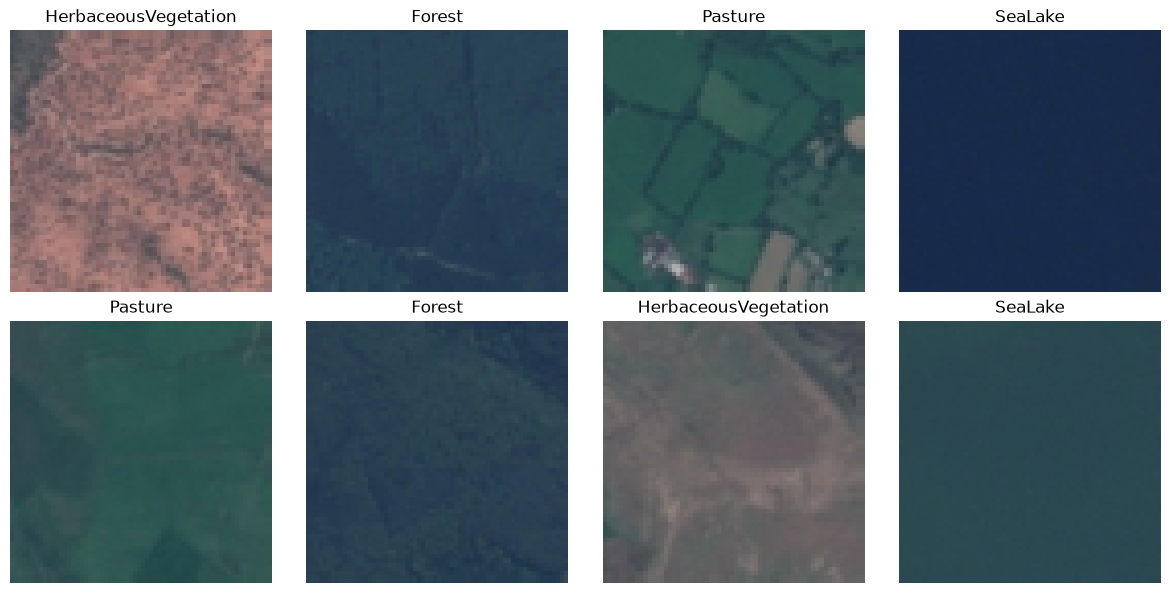

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = imagenes[i].permute(1, 2, 0)

    # Desnormalizamos para visualizar
    img = img * 0.5 + 0.5

    ax.imshow(img)
    ax.set_title(clases[etiquetas[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## **Modelo**

El modelo posee 4 bloques `Conv→BN→ReLU→Conv→BN→ReLU→MaxPool`, con los canales duplicándose y la resolución bajando a la mitad en cada bloque $64→32→16→8→4$.

In [13]:
import torch.nn.functional as F

class BloqueConv(nn.Module):
    """Dos convoluciones 3x3 que preservan el tamaño + pooling que lo reduce a la mitad."""
    def __init__(self, c_in, c_out):
        super().__init__()
        # bias=False porque BatchNorm ya aporta un término de desplazamiento
        self.conv1 = nn.Conv2d(c_in,  c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(c_out)
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        return self.pool(x)


class CNNPropia(nn.Module):
    def __init__(self, num_clases=10, canales=(32, 64, 128, 256),
                 dim_features=256, p_dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = canales

        self.bloque1 = BloqueConv(3,  c1)   # 3x64x64   -> c1 x 32 x 32
        self.bloque2 = BloqueConv(c1, c2)   # c1x32x32  -> c2 x 16 x 16
        self.bloque3 = BloqueConv(c2, c3)   # c2x16x16  -> c3 x  8 x  8
        self.bloque4 = BloqueConv(c3, c4)   # c3x8x8    -> c4 x  4 x  4

        self.flatten = nn.Flatten()
        self.fc1     = nn.Linear(c4 * 4 * 4, dim_features)
        self.dropout = nn.Dropout(p_dropout)
        self.fc2     = nn.Linear(dim_features, num_clases)

    def features(self, x):
        """Representación de la imagen JUSTO ANTES de la capa de clasificación.
        La vamos a reutilizar en el ejercicio 2 para t-SNE / PCA."""
        x = self.bloque1(x)
        x = self.bloque2(x)
        x = self.bloque3(x)
        x = self.bloque4(x)
        x = self.flatten(x)
        return F.relu(self.fc1(x))

    def forward(self, x):
        z = self.features(x)
        return self.fc2(self.dropout(z))   # logits crudos: los espera CrossEntropyLoss

In [14]:
def mostrar_shapes(modelo, input_shape=(3, 64, 64)):
    modelo = modelo.to(device).eval()
    hooks = []

    def hook(modulo, entrada, salida):
        print(f"{modulo.__class__.__name__:<12} -> {tuple(salida.shape)}")

    for m in modelo.modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
            hooks.append(m.register_forward_hook(hook))

    with torch.no_grad():
        y = modelo(torch.zeros(1, *input_shape, device=device))

    for h in hooks:
        h.remove()

    print(f"\nSalida final -> {tuple(y.shape)}")
    print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")


torch.manual_seed(100)          # re-fijamos la semilla justo antes de instanciar
modelo = CNNPropia().to(device)
mostrar_shapes(CNNPropia(num_clases=num_clases))

Conv2d       -> (1, 32, 64, 64)
Conv2d       -> (1, 32, 64, 64)
MaxPool2d    -> (1, 32, 32, 32)
Conv2d       -> (1, 64, 32, 32)
Conv2d       -> (1, 64, 32, 32)
MaxPool2d    -> (1, 64, 16, 16)
Conv2d       -> (1, 128, 16, 16)
Conv2d       -> (1, 128, 16, 16)
MaxPool2d    -> (1, 128, 8, 8)
Conv2d       -> (1, 256, 8, 8)
Conv2d       -> (1, 256, 8, 8)
MaxPool2d    -> (1, 256, 4, 4)
Flatten      -> (1, 4096)
Linear       -> (1, 256)
Linear       -> (1, 10)

Salida final -> (1, 10)
Parámetros entrenables: 2,224,618


## **Entrenamiento**

Definimos la función para calcular la norma del gradiente.

In [15]:
def normas_de_gradiente(modelo):
    """Norma del gradiente de los pesos de cada capa (convolusiones y densas)."""
    normas = {}
    for nombre, parametro in modelo.named_parameters():
        es_peso = nombre.endswith("weight")
        es_capa_de_interes = ("conv" in nombre) or ("fc" in nombre)   # se ignora la batch normalization
        if parametro.grad is not None and es_peso and es_capa_de_interes:
            normas[nombre] = parametro.grad.detach().norm(2).item()
    return normas

Definimos funciones auxiliares para el ciclo de entrenamiento:

In [16]:
learning_rate = 0.01
momentum = 0.9

criterio_opt = nn.CrossEntropyLoss()
optimizador = optim.SGD(modelo.parameters(), lr = learning_rate, momentum = momentum)

In [17]:
def inferencia(modelo, loader, criterio, device):
    '''Inferencia y evaluación del modelo (sin actualizar pesos).'''
    modelo.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs_td   = imgs.to(device)
            labels_td = labels.to(device)
            outputs = modelo(imgs_td)
            loss = criterio(outputs, labels_td)
            total_loss += loss.item() * labels_td.size(0)   # des-promediamos el batch
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels_td).sum().item()
            total   += labels_td.size(0)
    return total_loss / total, 100 * correct / total


def entrenar_una_epoca(modelo, loader, criterio, optimizador, device, grad_historial, registrar_grad=True):
    modelo.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs_td   = imgs.to(device)
        labels_td = labels.to(device)

        optimizador.zero_grad()
        outputs = modelo(imgs_td)
        loss = criterio(outputs, labels_td)
        loss.backward()

        # monitoreo del flujo de gradientes (antes del paso del optimizador)
        if registrar_grad:
            grad_historial.append(normas_de_gradiente(modelo))

        optimizador.step()

        total_loss += loss.item() * labels_td.size(0)
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels_td).sum().item()
        total   += labels_td.size(0)
    return total_loss / total, 100 * correct / total


def entrenar(modelo, train_loader, val_loader, criterio, optimizador,cant_epocas, device, epocas_con_grad=2):
    modelo = modelo.to(device)
    grad_historial = []
    historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoca in range(cant_epocas):
        t0 = time.time()

        train_loss, train_acc = entrenar_una_epoca(
            modelo, train_loader, criterio, optimizador, device,
            grad_historial, registrar_grad=(epoca < epocas_con_grad)
        )
        # En validación solo se hace inferencia, no se actualizan los pesos
        val_loss, val_acc = inferencia(modelo, val_loader, criterio, device)

        historial["train_loss"].append(train_loss)
        historial["train_acc"].append(train_acc)
        historial["val_loss"].append(val_loss)
        historial["val_acc"].append(val_acc)

        print(f"Época {epoca+1}/{cant_epocas} ({time.time()-t0:.0f}s) | "
              f"train: loss {train_loss:.4f}, acc {train_acc:.2f}% | "
              f"val: loss {val_loss:.4f}, acc {val_acc:.2f}%")

    print("Entrenamiento terminado.")
    return historial, grad_historial

In [16]:
cant_epocas = 20

torch.manual_seed(100)
modelo = CNNPropia(num_clases=num_clases).to(device)
optimizador = optim.SGD(modelo.parameters(), lr=learning_rate, momentum=momentum)

historial, grad_historial = entrenar(
    modelo, train_loader, val_loader,
    criterio_opt, optimizador, cant_epocas, device,
    epocas_con_grad=2
)

Época 1/20 (238s) | train: loss 1.0881, acc 61.48% | val: loss 1.4100, acc 58.49%
Época 2/20 (197s) | train: loss 0.7356, acc 74.48% | val: loss 0.8131, acc 72.10%
Época 3/20 (215s) | train: loss 0.5957, acc 79.75% | val: loss 1.8403, acc 68.99%
Época 4/20 (215s) | train: loss 0.5096, acc 82.74% | val: loss 0.5547, acc 81.95%
Época 5/20 (216s) | train: loss 0.4326, acc 85.71% | val: loss 0.6731, acc 77.88%
Época 6/20 (222s) | train: loss 0.3722, acc 87.47% | val: loss 0.3245, acc 89.48%
Época 7/20 (228s) | train: loss 0.3366, acc 88.88% | val: loss 0.3689, acc 87.63%
Época 8/20 (217s) | train: loss 0.2807, acc 90.62% | val: loss 0.2041, acc 93.14%
Época 9/20 (211s) | train: loss 0.2669, acc 91.25% | val: loss 0.3483, acc 88.22%
Época 10/20 (219s) | train: loss 0.2483, acc 91.77% | val: loss 0.2078, acc 93.28%
Época 11/20 (219s) | train: loss 0.2253, acc 92.42% | val: loss 0.3433, acc 90.05%
Época 12/20 (213s) | train: loss 0.2120, acc 93.17% | val: loss 0.2704, acc 91.16%
Época 13/20 (

## **Análisis gráfico**

Graficamos la evolución de la *loss* y del accuracy en entrenamiento y validación.

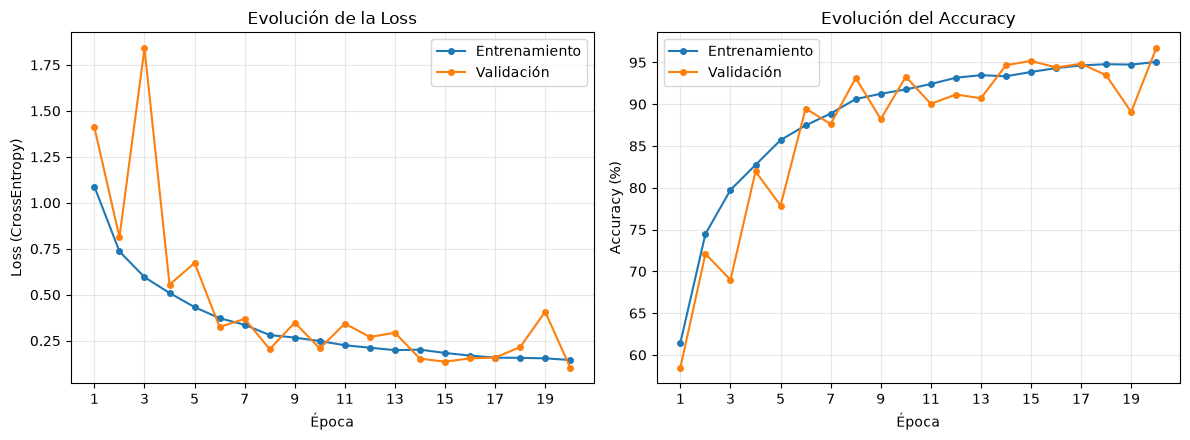

Mejor accuracy de validación: 96.69% (época 20)
Gap final train-val: -1.63 puntos


In [19]:
n_epocas = len(historial["train_loss"])
epocas = np.arange(1, n_epocas + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epocas, historial["train_loss"], marker="o", ms=4, label="Entrenamiento")
axes[0].plot(epocas, historial["val_loss"],   marker="o", ms=4, label="Validación")
axes[0].set_ylabel("Loss (CrossEntropy)")
axes[0].set_title("Evolución de la Loss")

axes[1].plot(epocas, historial["train_acc"], marker="o", ms=4, label="Entrenamiento")
axes[1].plot(epocas, historial["val_acc"],   marker="o", ms=4, label="Validación")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Evolución del Accuracy")

for ax in axes:
    ax.set_xlabel("Época")
    ax.set_xticks(epocas[::max(1, n_epocas // 10)])
    ax.grid(alpha=.3)
    ax.legend()

plt.tight_layout()
plt.show()

mejor = int(np.argmax(historial["val_acc"]))
print(f"Mejor accuracy de validación: {historial['val_acc'][mejor]:.2f}% (época {mejor + 1})")
print(f"Gap final train-val: {historial['train_acc'][-1] - historial['val_acc'][-1]:.2f} puntos")

Verificamos que no haya habido desvanecimiento ni explosión de gradientes.

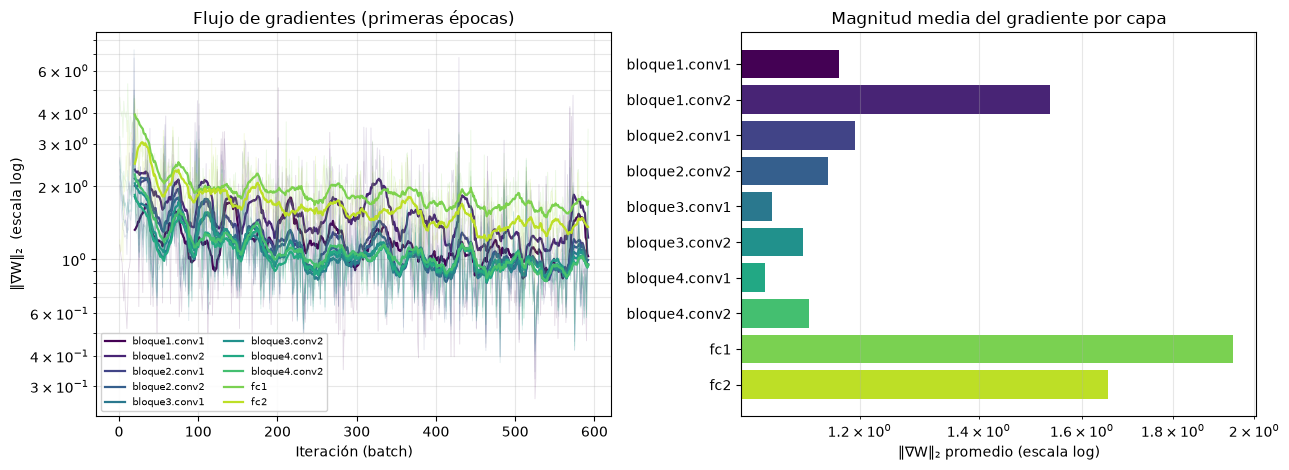

capa                       media      mínimo      máximo
bloque1.conv1           1.17e+00    2.67e-01    5.10e+00
bloque1.conv2           1.54e+00    3.22e-01    6.80e+00
bloque2.conv1           1.19e+00    3.44e-01    6.76e+00
bloque2.conv2           1.15e+00    3.96e-01    7.31e+00
bloque3.conv1           1.07e+00    3.75e-01    4.99e+00
bloque3.conv2           1.11e+00    3.98e-01    4.61e+00
bloque4.conv1           1.06e+00    4.40e-01    2.96e+00
bloque4.conv2           1.12e+00    5.28e-01    3.21e+00
fc1                     1.95e+00    9.19e-01    5.30e+00
fc2                     1.66e+00    7.53e-01    4.58e+00

Rango global de las normas: [2.67e-01, 7.31e+00]
Ratio entre la capa de mayor y la de menor gradiente medio: 1.8x


In [20]:
capas = list(grad_historial[0].keys())
etiquetas = [c.replace(".weight", "") for c in capas]
iteraciones = np.arange(1, len(grad_historial) + 1)
colores = plt.cm.viridis(np.linspace(0, .9, len(capas)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ventana = 20  # suavizado, para ver la tendencia y no solo el ruido del batch

for color, capa, etiqueta in zip(colores, capas, etiquetas):
    serie = np.array([h[capa] for h in grad_historial])
    suave = np.convolve(serie, np.ones(ventana) / ventana, mode="valid")
    axes[0].plot(iteraciones, serie, color=color, lw=.6, alpha=.15)
    axes[0].plot(iteraciones[ventana - 1:], suave, color=color, lw=1.6, label=etiqueta)

axes[0].set_yscale("log")
axes[0].set_xlabel("Iteración (batch)")
axes[0].set_ylabel("‖∇W‖₂  (escala log)")
axes[0].set_title("Flujo de gradientes (primeras épocas)")
axes[0].grid(alpha=.3, which="both")
axes[0].legend(fontsize=7, ncol=2, loc="lower left", framealpha=.9)

medias = [np.mean([h[c] for h in grad_historial]) for c in capas]
axes[1].barh(etiquetas, medias, color=colores)
axes[1].set_xscale("log")
axes[1].set_xlabel("‖∇W‖₂ promedio (escala log)")
axes[1].set_title("Magnitud media del gradiente por capa")
axes[1].grid(alpha=.3, axis="x", which="both")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"{'capa':<20}{'media':>12}{'mínimo':>12}{'máximo':>12}")
for capa, etiqueta in zip(capas, etiquetas):
    s = np.array([h[capa] for h in grad_historial])
    print(f"{etiqueta:<20}{s.mean():>12.2e}{s.min():>12.2e}{s.max():>12.2e}")

todas = np.array([[h[c] for c in capas] for h in grad_historial])
print(f"\nRango global de las normas: [{todas.min():.2e}, {todas.max():.2e}]")
print(f"Ratio entre la capa de mayor y la de menor gradiente medio: "
      f"{max(medias) / min(medias):.1f}x")

## **Análisis de Errores y Espacio Latente**

Hasta acá evaluamos el modelo sobre validación, que es el conjunto que usamos para monitorear el entrenamiento. Ahora lo evaluamos sobre el conjunto de test, para obtener una noción de la performance del modelo. Además de las métricas agregadas, se observa cómo la red organiza internamente las imágenes antes de tomar su decisión final.

Primero que nada, guardamos el estado del modelo en un archivo `modelo_custom.pt`. De este modo, se conservan los pesos del modelo entrenado para poder reutilizarlo sin tener que reentrenar.

In [21]:
torch.save(modelo.state_dict(), "modelo_custom.pt")

In [18]:
modelo = CNNPropia(num_clases=num_clases).to(device)
modelo.load_state_dict(torch.load("modelo_custom.pt", map_location=device))
modelo.eval()

CNNPropia(
  (bloque1): BloqueConv(
    (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloque2): BloqueConv(
    (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mo

Definimos una función que recorre el conjunto de test una única vez y devuelve, para cada imagen, su vector de *features*, su etiqueta real, la clase predicha y las probabilidades de cada clase.

Como el `loader` de test tiene `shuffle=False`, el orden de los resultados se corresponde con el de `test_data`, lo que nos permitirá recuperar después las imágenes mal clasificadas.

In [19]:
@torch.no_grad()
def evaluar_test(modelo, loader, device):
    """Devuelve (features, y_true, y_pred, probabilidades) en una sola pasada."""
    modelo.eval()
    feats, y_true, y_pred, probs = [], [], [], []
    for imgs, labels in loader:
        imgs = imgs.to(device, non_blocking=True)
        z = modelo.features(imgs)   # (Justo antes del clasificador
        logits = modelo.fc2(z)      # En eval, dropout = identidad
        feats.append(z.cpu())
        probs.append(logits.softmax(1).cpu())
        y_pred.append(logits.argmax(1).cpu())
        y_true.append(labels)
    return (torch.cat(feats).numpy(), torch.cat(y_true).numpy(),
            torch.cat(y_pred).numpy(), torch.cat(probs).numpy())

features_test, y_true, y_pred, probs_test = evaluar_test(modelo, test_loader, device)
print("features:", features_test.shape)   # (4050, 256)

features: (4050, 256)


Reportamos las métricas de clasificación sobre test. Incluimos el **F1 macro** además del **accuracy**. Como promedia el **F1** de cada clase sin ponderar por su frecuencia, una diferencia marcada entre ambas métricas puede ayudar a discernir si el modelo funciona bien en promedio pero falla sistemáticamente en alguna clase puntual.

In [20]:
from sklearn.metrics import classification_report, accuracy_score, f1_score
import pandas as pd

print(f"Accuracy en test: {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"F1 macro: {f1_score(y_true, y_pred, average='macro'):.4f}\n")

print(classification_report(y_true, y_pred, target_names=clases, digits=3))

Accuracy en test: 96.37%
F1 macro: 0.9630

                      precision    recall  f1-score   support

          AnnualCrop      0.934     0.973     0.953       450
              Forest      0.991     0.984     0.988       450
HerbaceousVegetation      0.903     0.956     0.929       450
             Highway      0.973     0.957     0.965       375
          Industrial      0.978     0.968     0.973       375
             Pasture      0.956     0.943     0.950       300
       PermanentCrop      0.964     0.931     0.947       375
         Residential      0.976     0.987     0.981       450
               River      0.980     0.925     0.952       375
             SeaLake      0.991     0.993     0.992       450

            accuracy                          0.964      4050
           macro avg      0.965     0.962     0.963      4050
        weighted avg      0.964     0.964     0.964      4050



In [21]:
rep = classification_report(y_true, y_pred, target_names=clases,digits=3, output_dict=True)
df_rep = pd.DataFrame(rep).T.round(3)
df_rep.head(10)

,precision,recall,f1-score,support
AnnualCrop,0.934,0.973,0.953,450.0
Forest,0.991,0.984,0.988,450.0
HerbaceousVegetation,0.903,0.956,0.929,450.0
Highway,0.973,0.957,0.965,375.0
Industrial,0.978,0.968,0.973,375.0
Pasture,0.956,0.943,0.950,300.0
PermanentCrop,0.964,0.931,0.947,375.0
Residential,0.976,0.987,0.981,450.0
River,0.980,0.925,0.952,375.0
SeaLake,0.991,0.993,0.992,450.0


Generamos la matriz de confusión sobre el conjunto de test. Cada fila corresponde a una clase real y cada columna a la clase predicha por el modelo, de modo que la diagonal contiene los aciertos y cada celda fuera de ella indica cuántas imágenes de una clase fueron asignadas a otra.

Cabe aclarar que las clases de EuroSAT no tienen exactamente la misma cantidad de imágenes. El conjunto de test contiene 450 imágenes de las clases más numerosas, 375 de las intermedias y 300 de `Pasture`. Por eso, para comparar el desempeño entre clases conviene fijarse en el *recall* reportado en la tabla de métricas, mientras que la matriz sirve más para identificar hacia qué clases se desvían los errores de cada una.

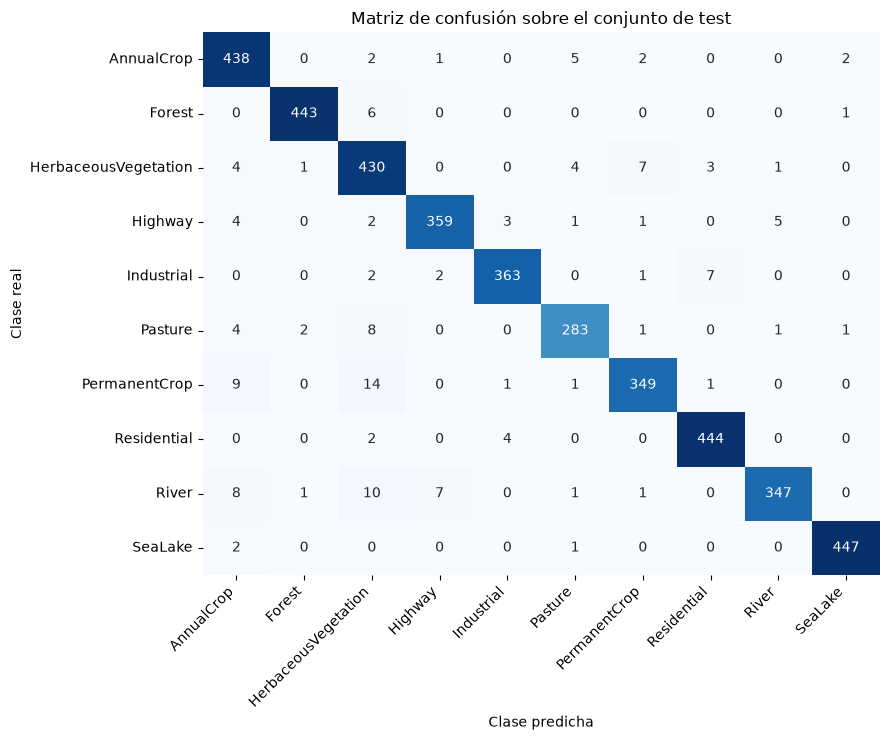

In [22]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=clases, yticklabels=clases, ax=ax)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión sobre el conjunto de test")
ax.tick_params(axis="y", rotation=0)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

Finalmente, proyectamos el espacio latente. Tomamos los vectores de 256 dimensiones extraídos antes de la capa de clasificación y los reducimos a 2 dimensiones para visualizar cómo la red organiza internamente las imágenes antes de tomar su decisión.

Se estandariza las features y aplicamos primero **PCA** a 50 componentes lo cual elimina el ruido y reduce considerablemente el costo computacional del paso siguiente, que es el recomendado antes de aplicar **t-SNE** sobre datos de alta dimensión. Sobre esas 50 componentes corremos t-SNE con `perplexity` 30 (vecinos más cercanos).

Conviene aclarar que **t-SNE** preserva la estructura local de los datos (qué puntos son vecinos de cuáles) pero no las distancias globales, ni la separación entre clusters, ni su tamaño relativo admiten una interpretación directa. Lo que sí podemos leer del gráfico es **si los puntos de una misma clase se agrupan entre sí y cuáles clases se solapan**.

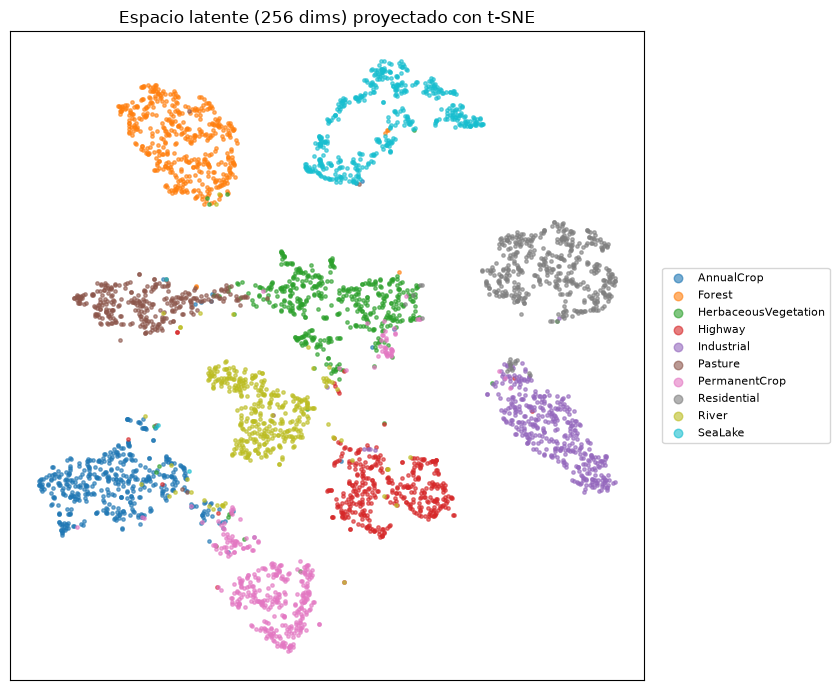

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

X_std   = StandardScaler().fit_transform(features_test)
X_pca50 = PCA(n_components=50, random_state=100).fit_transform(X_std)
X_tsne  = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=100).fit_transform(X_pca50)

fig, ax = plt.subplots(figsize=(8.5, 7))
for i, c in enumerate(clases):
    m = y_true == i
    ax.scatter(X_tsne[m,0], X_tsne[m,1], s=6, alpha=.6, label=c, color=plt.cm.tab10(i/10))
ax.set_title("Espacio latente (256 dims) proyectado con t-SNE")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1.02, .5))
plt.tight_layout(); plt.show()